## Definition of ADAM

**Adam** is an adaptive learning rate optimization algorithm that calculates individual learning rates for different parameters by combining two concepts: **Momentum** (tracking the mean of past gradients) and **RMSprop** (tracking the uncentered variance of past gradients).

**AdamW** is a direct mathematical fix to Adam that properly decouples weight decay (L2 regularization) from the gradient update step, preventing regularization from being incorrectly scaled by historical gradient magnitudes.

---

### How Adam Works: The Two "Moments"

To understand why Adam is so powerful, you have to look at how it keeps track of two rolling averages (called "moments") of the gradients during training:

1. **First Moment ($m_t$ - The Mean / Momentum):**
* This tracks the *direction* of the gradients over time.
* Just like a heavy boulder rolling down a hill, momentum helps the optimizer build speed in consistent directions and smooth out erratic, noisy zigzags caused by mini-batch training.
* Controlled by hyperparameter $\beta_1$ (usually set to $0.9$).


2. **Second Moment ($v_t$ - The Uncentered Variance / RMSprop):**
* This tracks the *magnitude* or spread of past squared gradients.
* If a parameter receives massive, violent gradient updates, $v_t$ grows large, causing Adam to shrink its effective learning rate for that specific parameter. If gradients are tiny, $v_t$ stays small, boosting the effective learning rate. This gives every parameter its own custom learning rate.
* Controlled by hyperparameter $\beta_2$ (usually set to $0.999$).



#### Bias Correction

Because both $m_t$ and $v_t$ are initialized at zero, they tend to be heavily biased toward zero during the initial steps of training (especially when $\beta_1$ and $\beta_2$ are close to $1$). Adam includes a clever **bias correction** step that scales up these estimates early in training so the network doesn't take sluggish steps at epoch 1.

---

### What Makes AdamW Different? (The True Standard)

While standard Adam was a revolution when it was introduced in 2014, researchers eventually discovered a flaw in how it handled **L2 Regularization** (weight decay, which prevents overfitting by penalizing large weights).

* In **Standard Adam**, L2 regularization was lumped directly into the gradient calculation. This meant parameters with large historical gradients received *less* regularization penalty than parameters with small historical gradients—an unintended side effect.
* In **AdamW**, **weight decay is decoupled**. The regularization penalty is applied directly to the weights *after* the adaptive gradient step has occurred.

This seemingly small mathematical correction drastically improved generalization performance, making **AdamW** the absolute gold standard for training Transformers, diffusion models, and complex neural networks today.

---

### Why is it the Undisputed Heavyweight?

* **Set-and-Forget Convenience:** Unlike basic SGD, which requires meticulous manual tuning of learning rate schedules and momentum values to get good results, Adam/AdamW works remarkably well out-of-the-box with default settings.
* **Handles Sparse Data & Noisy Gradients:** Because it scales learning rates per parameter, it excels on complex datasets with sparse features or noisy gradients.
* **Fast Initial Convergence:** It drops the loss value down rapidly during the early stages of training.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

## Library Imports and Dependencies

In this initial cell, we set up our development workspace by importing all the necessary modules:
- **`torch` & `torch.nn`**: PyTorch's core framework and neural network module (`nn`), used to build and train the network.
- **`torch.optim`**: Contains optimization algorithms, including the advanced **AdamW** optimizer.
- **`sklearn.datasets.make_classification`**: Generates a synthetic dataset optimized for multi-class classification tasks.
- **`sklearn.model_selection.train_test_split`**: Splits the generated dataset into separate subsets for model training and testing.
- **`sklearn.preprocessing.StandardScaler`**: Scales our data features so that they have a mean of $0$ and a standard deviation of $1$.

In [2]:
# 1. Generate Vehicle Telemetry Dataset (4 features, 3 classes)
X_raw, y_raw = make_classification(
    n_samples=2000,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

## Synthetic Dataset Generation

To simulate real-world vehicle diagnostic telemetry, we construct a synthetic classification dataset:
- **`n_samples=2000`**: Creates $2000$ unique sample instances.
- **`n_features=4` & `n_informative=4`**: Sets exactly $4$ variables containing meaningful classification signals.
- **`n_classes=3`**: Configures a target label containing $3$ unique classes (e.g., *Healthy*, *Warning*, or *Critical*).
- **`test_size=0.2`**: Reserves $20\%$ of the data ($400$ samples) for validation and $80\%$ ($1600$ samples) for actual model training.

In [3]:
# 2. Preprocess and Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

## Feature Scaling & PyTorch Tensor Conversion

Features with large ranges can bias neural network weights and lead to unstable gradient updates. Here, we preprocess the raw attributes:
1. **Standard Standardization**: We fit our `StandardScaler` on the training subset to compute feature statistics (mean and variance), and apply the transformation to scale both the training and test sets.
2. **Tensor Conversion**: PyTorch models do not accept standard NumPy arrays directly. We convert the scaled inputs to `torch.float32` tensors and target class labels to 64-bit integer tensors (`torch.long`).

In [4]:
# 3. Define the MLP Architecture
class VehicleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(VehicleMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, 16),
            nn.ReLU(),
            nn.Linear(16, output_dim) # Outputs raw logits for CrossEntropyLoss
        )

    def forward(self, x):
        return self.network(x)

model = VehicleMLP(input_dim=4, hidden_dim=32, output_dim=3)
criterion = nn.CrossEntropyLoss()

## Building the Multi-Layer Perceptron (MLP)

We define our network architecture by subclassing `nn.Module` to create a `VehicleMLP` classifier:
- **Input Layer**: Takes our $4$ scaled telemetry features.
- **First Hidden Layer**: Features $32$ fully-connected neurons followed by a **ReLU** non-linear activation.
- **Dropout Regularization**: A `Dropout(0.2)` layer randomly deactivates $20\%$ of neural activations during forward propagation to mitigate overfitting.
- **Second Hidden Layer**: Scales features down to $16$ neurons with another **ReLU** activation.
- **Output Projection Layer**: Spits out $3$ raw unnormalized outputs (logits) representing our three vehicle states.

In [5]:
# 4. Initialize the AdamW Optimizer
# Notice the explicit weight_decay parameter, which applies proper L2 regularization
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.01,            # Learning rate
    weight_decay=0.01,  # Penalizes large, overly complex weights to prevent overfitting
    betas=(0.9, 0.999)  # Default momentum and uncentered variance decay rates
)

## Initializing the AdamW Optimizer

We instantiate our optimizer using **AdamW**:
- **`lr=0.01`**: Sets the initial step size.
- **`weight_decay=0.01`**: Applies decoupled L2 weight regularization directly to parameter updates to prevent the network weights from exploding in size.
- **`betas=(0.9, 0.999)`**: Default settings for gradient momentum tracking (moving averages of gradients and squared gradients).

In [6]:
# 5. Training Loop
epochs = 100
print("--- Training MLP with AdamW ---")
for epoch in range(epochs):
    model.train()

    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass & optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {loss.item():.4f}")

--- Training MLP with AdamW ---
Epoch [20/100] | Loss: 0.6763
Epoch [40/100] | Loss: 0.5408
Epoch [60/100] | Loss: 0.4544
Epoch [80/100] | Loss: 0.4055
Epoch [100/100] | Loss: 0.3459


## Model Training Loop

We train our model over $100$ full passes (epochs) through our dataset:
1. **Active Training Mode**: `model.train()` enables Dropout layer operations.
2. **Forward Propagation**: Feeds `X_train_t` to the model to compute predictions and computes loss against target labels using `CrossEntropyLoss`.
3. **Backpropagation**: Gradients are cleared via `optimizer.zero_grad()`, calculated with `loss.backward()`, and applied to update the model weights using `optimizer.step()`.

In [7]:
# 6. Evaluation on Test Set
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_t).sum().item() / y_test_t.size(0)
    print(f"\nFinal Test Accuracy: {accuracy * 100:.2f}%")


Final Test Accuracy: 86.25%


## Final Model Evaluation

Lastly, we evaluate the generalizability of our trained model on the unseen test set:
- **Inference Mode**: `model.eval()` turns off dropout layers, and `with torch.no_grad()` blocks PyTorch from tracking gradients, which significantly speeds up computation and saves system memory.
- **Accuracy Check**: We match the highest predicted probability indexes against the ground truth labels `y_test_t` to determine the classifier's performance accuracy.

Combining the **AdamW optimizer** with a **Cosine Annealing learning rate scheduler** is one of the most powerful and widely used recipes in modern deep learning (from training standard MLPs to massive Large Language Models).

While AdamW manages *how* each parameter updates based on gradients and weight decay, the scheduler manages *the overall step size* (learning rate) as training progresses.

---

### Why Cosine Annealing?

During the early stages of training, a **higher learning rate** helps the model make rapid progress and escape shallow local minima. However, as training nears completion, a high learning rate causes the weights to bounce around erratically, preventing the model from settling into the sharpest, most accurate minimum.

**Cosine Annealing** solves this by smoothly decaying the learning rate following the shape of a cosine wave:

* It starts high, drops off very slowly in the middle of training, accelerates its decay toward the end, and flattens out at a minimum learning rate.

Mathematically, the learning rate $\eta_t$ at epoch $t$ is calculated as:


$$\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})\left(1 + \cos\left(\frac{T_{\text{cur}}}{T_{\max}}\pi\right)\right)$$

* $\eta_{\max}$ & $\eta_{\min}$: Starting and minimum learning rates.
* $T_{\text{cur}}$: Current epoch number.
* $T_{\max}$: Total number of epochs for a half-cosine cycle.

---

### PyTorch Implementation: AdamW + Cosine Annealing

Here is how you integrate `torch.optim.lr_scheduler.CosineAnnealingLR` directly into our vehicle classification training loop:

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Libraries & Imports for the Scheduled Workflow

In this cell, we import the foundational libraries required for training our optimized PyTorch model:
- **`torch`**: The core deep learning library used for computations and gradient tracking.
- **`torch.nn`**: PyTorch's neural network module containing linear layers, activation functions, and losses.
- **`torch.optim`**: Contains optimization algorithms including our selected **AdamW** optimizer.
- **`sklearn` Modules**: Used for generating artificial synthetic dataset samples, splitting arrays, and standardizing features for numerical stability.

In [10]:
# 1. Generate & Preprocess Data
X_raw, y_raw = make_classification(n_samples=2000, n_features=4, n_informative=4, n_redundant=0, n_classes=3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

## Dataset Generation, Splitting & Normalization

Here, we prepare our data for training the PyTorch classifier:
1. **Generate Dataset**: We use `make_classification` to build a synthetic dataset with 2000 samples, 4 features (all of which are highly informative), and 3 distinct target classes.
2. **Split Subset**: We partition our dataset into an $80\%$ training set ($1600$ records) and a $20\%$ testing set ($400$ records).
3. **Normalize Features**: We scale the features using `StandardScaler` to have a mean of $0$ and a standard deviation of $1$.
4. **Cast to Tensors**: The normalized numpy arrays are converted into standard PyTorch float tensors, and class labels are converted into 64-bit integer tensors (`long`).

In [11]:
# 2. Define MLP Model
class VehicleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )
    def forward(self, x):
        return self.network(x)

model = VehicleMLP()
criterion = nn.CrossEntropyLoss()

## Multi-Layer Perceptron (MLP) Model Definition

This cell defines our Neural Network model architecture and the training objective:
- **`VehicleMLP` Class**: Inherits from PyTorch's `nn.Module` class. It specifies an sequential network containing an input layer taking 4 features, a hidden layer projecting to 32 neurons, a **ReLU** activation layer, a **Dropout(0.2)** regularizer to avoid overfitting, another linear layer downsampling to 16 neurons with **ReLU**, and a final projection layer outputing 3 raw values.
- **`CrossEntropyLoss`**: Our loss function. It measures the performance of our multi-class output values.

In [12]:
# 3. Initialize AdamW Optimizer
epochs = 100
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.02,            # Initial peak learning rate (eta_max)
    weight_decay=0.01   # Decoupled weight decay
)



## AdamW Optimizer Instantiation

We instantiate our optimizer using **AdamW**:
- We pass `model.parameters()` to allow the optimizer to track and update the model weights.
- **`lr=0.02`**: This defines our peak learning rate ($0.02$). It acts as the maximum learning rate bound ($\eta_{\max}$) for our learning rate scheduler.
- **`weight_decay=0.01`**: Implements decoupled weight regularization to penalize complex models and enforce generalization during training.

In [13]:
# 4. Initialize Cosine Annealing Scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,       # Number of epochs for the learning rate to decay to eta_min
    eta_min=1e-4        # The lowest learning rate at the very end of training
)

## Cosine Annealing Scheduler Initialization

Here we define our learning rate decay strategy using a **Cosine Annealing** learning rate scheduler:
- **`T_max=epochs`**: Configures the scheduler to decay the learning rate gradually over $100$ epochs.
- **`eta_min=1e-4`**: Sets the minimum learning rate floor to $0.0001$. As the epochs approach 100, the optimizer's active learning rate will gracefully slow down and flatten out at this value to allow stable training stabilization.

In [14]:
# 5. Training Loop with Scheduler Step
print("--- Training MLP with AdamW & Cosine Annealing ---")
for epoch in range(epochs):
    model.train()

    # Forward pass & loss calculation
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass & optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Step the scheduler at the end of each epoch
    scheduler.step()

    # Print progress and current learning rate
    if (epoch + 1) % 20 == 0:
        current_lr = scheduler.get_last_lr()[0]
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {loss.item():.4f} | Current LR: {current_lr:.6f}")

--- Training MLP with AdamW & Cosine Annealing ---
Epoch [20/100] | Loss: 0.5747 | Current LR: 0.018100
Epoch [40/100] | Loss: 0.4227 | Current LR: 0.013125
Epoch [60/100] | Loss: 0.3809 | Current LR: 0.006975
Epoch [80/100] | Loss: 0.3620 | Current LR: 0.002000
Epoch [100/100] | Loss: 0.3572 | Current LR: 0.000100


## Supercharged Training Loop with Scheduler Steps

We execute the 100-epoch training loop using our active schedule:
1. **Forward Pass**: Feeds the standardized input features to calculate prediction logits.
2. **Backpropagation**: Calculates error gradients and applies updates via our **AdamW** optimizer.
3. **Scheduler Update**: `scheduler.step()` is called once per epoch after our weight updates. This systematically reduces the base learning rate according to the cosine decay trajectory.
4. **Telemetry Logs**: Every 20 epochs, we query the optimizer's current active learning rate via `scheduler.get_last_lr()[0]` and print it along with the current training loss.

---

### Key Things to Remember

1. **`scheduler.step()` placement:** In PyTorch, epoch-based schedulers like `CosineAnnealingLR` should be called **once per epoch** (after your training loop finishes the epoch batches), whereas optimizer `.step()` is usually called per batch.
2. **The `T_max` parameter:** This tells the scheduler how long the cosine curve should take to reach its minimum value (`eta_min`). If your training runs longer than `T_max`, PyTorch will begin repeating or cycling the cosine curve depending on configuration.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Libraries & Environment Setup

Before starting our deep learning workflow, we import the fundamental modules required for data handling, preprocessing, model design, optimization, and visualization:

* **`torch` & `torch.nn`**: The foundational frameworks for building deep neural networks with PyTorch.
* **`torch.optim`**: Contains optimization algorithms, specifically the adaptive **AdamW** optimizer.
* **`sklearn` (Scikit-Learn)**: Utilized here to generate synthetic telemetry data, split it into train/test sets, and scale features for stability.
* **`matplotlib.pyplot`**: Used to construct visual charts tracking the optimization dynamics (loss decay and learning rate curves).

In [17]:
# 1. Generate & Preprocess Data (using the corrected parameters)
X_raw, y_raw = make_classification(
    n_samples=2000,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

Synthetic Telemetry Data Generation & Splitting

In this step, we generate a synthetic 3-class classification problem representing vehicle telemetry data.

### Mathematical Alignment
Using Scikit-Learn's `make_classification`, we configure:
- `n_samples=2000`: Generates 2,000 telemetry records.
- `n_features=4` & `n_informative=4`: Every single feature contains meaningful predictive signals.
- `n_classes=3`: Sets up a multi-class classification task (e.g., Classifying a vehicle state into *Normal*, *Warning*, or *Critical*).

### The Data Split
We divide the generated arrays into training ($80\%$) and testing ($20\%$) subsets:

$$\text{Total Samples (2000)} \longrightarrow \begin{cases} \text{Train Set (1600 samples)} \\ \text{Test Set (400 samples)} \end{cases}$$

Finally, we fit a `StandardScaler` on the training dataset to ensure every input feature has a mean of $0$ and a standard deviation of $1$. This prevents scale-dominant features from destabilizing our neural weights. We then cast these numpy arrays to **PyTorch Tensors** (`torch.float32` for inputs, `torch.long` for target classes).

In [18]:
# 2. Define MLP Model Architecture
class VehicleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )
    def forward(self, x):
        return self.network(x)

model = VehicleMLP()
criterion = nn.CrossEntropyLoss()

Neural Network Architecture (Multi-Layer Perceptron)

We construct a deep **Multi-Layer Perceptron (MLP)** called `VehicleMLP`. Below is a schematic breakdown of how information flows through this model's layers:

```
Input Vector (4 features)
       │
       ▼
┌──────────────┐
│ Linear Layer │  ──> Outputs 32 nodes
└──────────────┘
       │
       ▼
┌──────────────┐
│     ReLU     │  ──> Introduces non-linearity: f(x) = max(0, x)
└──────────────┘
       │
       ▼
┌──────────────┐
│ Dropout(0.2) │  ──> Randomly zeroes 20% of activations to combat overfitting
└──────────────┘
       │
       ▼
┌──────────────┐
│ Linear Layer │  ──> Downsamples from 32 nodes to 16 nodes
└──────────────┘
       │
       ▼
┌──────────────┐
│     ReLU     │  ──> Second non-linear threshold
└──────────────┘
       │
       ▼
┌──────────────┐
│ Linear Layer │  ──> Final projection to 3 classes (outputs raw logits)
└──────────────┘
```

### Loss Function
We instantiate the `CrossEntropyLoss` criterion. It automatically applies a LogSoftmax normalization over the 3 raw output logits, computing negative log-likelihood loss against our integer targets.

In [19]:
# 3. Initialize AdamW & Cosine Annealing Scheduler
epochs = 100
optimizer = optim.AdamW(model.parameters(), lr=0.02, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-4)

# Lists to store history for plotting
loss_history = []
lr_history = []

Optimization Strategy (AdamW & Cosine Annealing)

This cell instantiates the backbone of modern neural network optimization: **AdamW** paired with a **Cosine Annealing** Learning Rate Scheduler.

### Decoupled Weight Decay (AdamW)
Unlike basic SGD or traditional Adam where L2 weight regularization is mathematically tangled within the gradient moments, **AdamW** subtracts a small fraction of the weights ($0.01$ times the weight) directly during the parameter update step:

$$\theta_{t+1} = \theta_t - \eta_t \cdot \text{AdamUpdate}(\nabla \theta_t) - \eta_t \cdot \lambda \cdot \theta_t$$

*Where $\lambda$ is the `weight_decay` parameter and $\eta_t$ is the dynamic learning rate.* This improves generalization and makes regularizing deep models extremely effective.

### Cosine Annealing LR Schedule
We configure the scheduler with `T_max=epochs` (100). This instructs PyTorch to smoothly drop the learning rate from its initial value ($0.02$) to the designated minimum threshold (`eta_min=1e-4`) using a half-cosine wave pattern over the course of 100 epochs.

In [20]:
# 4. Training Loop
print("--- Training MLP and Tracking Metrics ---")
for epoch in range(epochs):
    model.train()

    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Capture metrics before stepping scheduler
    current_lr = scheduler.get_last_lr()[0]
    lr_history.append(current_lr)
    loss_history.append(loss.item())

    scheduler.step()

--- Training MLP and Tracking Metrics ---


The Training Loop with Metric Tracking

With our data, model architecture, optimizer, and scheduler ready, we launch the training process over $100$ full cycles (epochs). Within each epoch:

1. **Set Model to Train Mode**: `model.train()` enables features like Dropout to active state.
2. **Forward Pass**: Evaluates inputs `X_train_t` through the model to acquire predicted logits.
3. **Loss Calculation**: Computes the difference between predicted logits and actual labels (`y_train_t`).
4. **Backward Pass**: `loss.backward()` propagates gradients backwards through the weights using automatic differentiation.
5. **Weight Update**: `optimizer.step()` updates the model's weights according to AdamW dynamics.
6. **Metric Logging**: We extract the exact learning rate using `scheduler.get_last_lr()[0]` and append both learning rate and loss to our history lists.
7. **Scheduler Step**: `scheduler.step()` adjusts the global base learning rate downward according to our cosine decay formula.

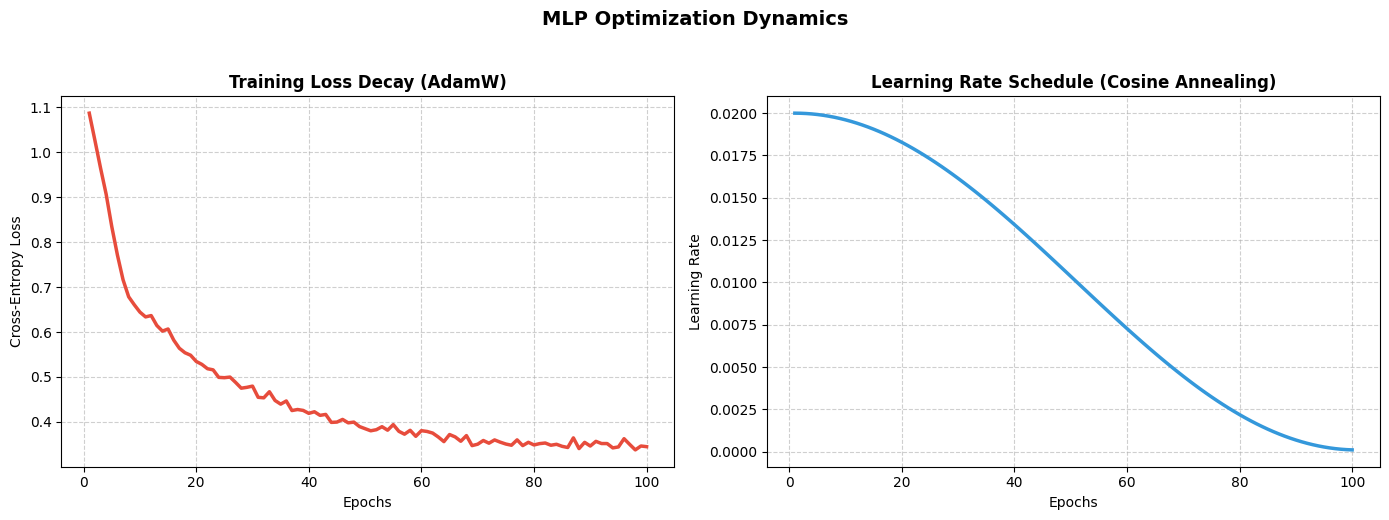

In [21]:
# 5. Plotting the Graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Training Loss Curve
axes[0].plot(range(1, epochs + 1), loss_history, color='#e74c3c', linewidth=2.5)
axes[0].set_title('Training Loss Decay (AdamW)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Learning Rate Schedule Curve
axes[1].plot(range(1, epochs + 1), lr_history, color='#3498db', linewidth=2.5)
axes[1].set_title('Learning Rate Schedule (Cosine Annealing)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('Learning Rate', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('MLP Optimization Dynamics', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

Visual Analysis of Optimization Dynamics

The matplotlib visualizations above display the exact relationship between our loss minimization and the learning rate's decay pattern:

* **Left Chart (Training Loss Decay)**: Notice how the Cross-Entropy loss plummets extremely fast in the early epochs and continues to shrink consistently.
* **Right Chart (Learning Rate Schedule)**: Demonstrates the perfect half-cosine curve. It starts high at $0.02$, decreases slowly, rapidly drops in the middle, and flattens out smoothly as it approaches $0.0001$.

This visual confirms that the model optimization process was extremely stable and reached convergence safely!